# 14 - Repeated Splits, Group Bootstrap, and Paired Tests over Acquisitions

## The objection (R2C5)

Table 14 reports a Friedman test with chi-square 35.43 and p = 3.6e-06, computed over
**six balancing strategies as blocks** and seven classifiers as treatments, on one
partition of one dataset. The reviewer is right that this is not a valid application of
the Demsar framework:

* The six strategies are not independent replicates. They resample **the same training
  rows**, evaluated on **the same test rows**, from **the same partition**. Almost every
  source of variance is shared, so the residual differences are far smaller than the test
  assumes, and the p-value is correspondingly overstated.
* A single partition gives no estimate of partition variance at all. If a different seed
  would have moved macro-F1 by three points, the reported ranking is noise.
* Window-level confidence intervals treat 11,334 windows that overlap by 75% as 11,334
  independent observations, which understates their width by a large factor.

## What replaces it

| # | Test | Unit of replication | Answers |
|---|---|---|---|
| 1 | Repeated group-aware splits | one partition, five seeds | how much does the result move if the cut falls elsewhere? |
| 2 | Group-level bootstrap | one recording / acquisition date | how wide is the interval once dependence is respected? |
| 3 | Paired Wilcoxon over held-out acquisitions | one held-out recording / date | is one condition really better, on units that are independent by construction? |

Test 3 is the direct replacement for the Friedman test: same six balancing strategies,
same classifier, but blocked on **separate acquisitions** instead of on configurations of
one acquisition.

## A documented approximation

Features exist only for the rows that survived the guard band and decimation of the
original partition. Re-splitting with a different seed moves the guard band, so a strictly
correct repeat would need re-extraction. We instead re-partition **the rows that already
have features**, which keeps the population fixed across repeats and isolates partition
variance. This is stated in the paper; it slightly understates variability, because the
population itself was chosen under seed 42.

In [1]:
import sys, json, time
from pathlib import Path
# No machine-specific path: the kernel starts in Experiment/ (or the repo root).
EXPERIMENT_DIR = Path.cwd() if (Path.cwd() / "dasfe").is_dir() else Path.cwd() / "Experiment"
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dasfe import config as C, fusion as F, evaluate as EV, robust as R

sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURE ME -----------------------------
DATASETS   = ("tomasov", "cao")
FEATURE_SET = "full_1002"          # matches the headline row of main_results.csv

# The configuration each dataset reports as its headline result is read
# from notebook 07's model card (below), so the bootstrap follows whatever
# that run selected instead of a value copied from an earlier run.

# Test 1: which conditions to track across repeated partitions.
REPEAT_CONFIGS = [("LightGBM", "class_weight"),
                  ("RandomForest", "class_weight"),
                  ("LogisticRegression", "class_weight")]
N_REPEATS  = 5

# Test 3: the six balancing strategies, one classifier - the direct replacement
# for the retired Friedman test.
PAIRED_CONFIGS = [("LightGBM", s) for s in C.BALANCING_STRATEGIES]

# Grouping columns.  The first is the leave-one-out unit; the bootstrap ladder
# runs from the naive window level up to it.
GROUP_COLS = {"tomasov": {"loo": "recording_id",
                          "ladder": ("zone_id", "recording_id")},
              "cao":     {"loo": "date_id",
                          "ladder": ("session_id", "date_id")}}

N_BOOT     = 2000
# Stratified caps.  None uses every row; the repeated-split and leave-one-out
# sweeps refit many times, so they are capped to stay tractable on the Jetson.
# At 8000/class the Tomasov repeated-split sweep took 3,870 s for 15 fits, so
# the leave-one-out sweep (6 strategies x 13 recordings = 78 fits) is capped
# harder: 6000 would cost roughly 4.3 hours, 3000 roughly 2.
REPEAT_PER_CLASS = 8000
LOO_PER_CLASS    = 3000

# Reuse the expensive sweeps when their CSV already exists.  Set False to force
# a recomputation.  This exists because the first run crashed in the plotting
# cell after the 65-minute repeated-split sweep had already succeeded.
REUSE_CACHED = True
# ------------------------------------------------------------------------

out_dir = C.results_dir("shared", "14_statistics")
print("output:", out_dir)

CARDS = {ds: json.loads((C.results_dir(ds, "07_final", FEATURE_SET) / "model_card.json")
                        .read_text(encoding="utf-8")) for ds in DATASETS}
HEADLINE = {ds: (c["model"], c["balancing"]) for ds, c in CARDS.items()}
print("headline:", HEADLINE)

DATA = {}
for ds in DATASETS:
    d = F.load(C.results_dir(ds, "04_fusion"))
    d["manifest"] = d["manifest"].reset_index(drop=True)
    d["split"] = d["manifest"]["split"].to_numpy()
    DATA[ds] = d
    print(f"{ds:9s} X {d['X'].shape}  {len(set(d['y']))} classes  "
          f"{d['manifest'][GROUP_COLS[ds]['loo']].nunique()} "
          f"{GROUP_COLS[ds]['loo']} units")

output: /mnt/b6bdcd1c-136a-435b-aeed-0e1b31c32749/Paper_Reeyan/Results/shared/14_statistics
tomasov   X (172458, 1002)  9 classes  16 recording_id units
cao       X (15418, 1002)  6 classes  21 date_id units


## 0. The test being retired

Restated here so the revision is auditable: what was claimed, and why it does not hold.

In [2]:
old_path = (C.RESULTS_DIR / "shared" / f"09_report_{FEATURE_SET}" / "tables"
            / "statistical_tests.csv")
if old_path.exists():
    old = pd.read_csv(old_path)
    display(old)
    print("Blocks: the six balancing strategies. Treatments: the seven classifiers.")
    print("Every block reuses the same rows, the same partition and the same features,")
    print("so the blocks are not independent replicates and the p-value is not valid.")
else:
    old = None
    print("previous statistical_tests.csv not found at", old_path)

,dataset,friedman_chi2,friedman_p,iman_davenport_F,critical_difference,best_model,best_avg_rank
0,cao,35.429,0.000004,310.0,3.677,LightGBM,1.0
1,tomasov,35.357,0.000004,275.0,3.677,HistGradientBoosting,1.5


Blocks: the six balancing strategies. Treatments: the seven classifiers.
Every block reuses the same rows, the same partition and the same features,
so the blocks are not independent replicates and the p-value is not valid.


## 1. Repeated group-aware partitions

Five partitions of the same population, each built with the same leakage-safe rule and a
different seed. Tomasov re-cuts equal-mass contiguous segments per recording and re-applies
the guard band; Cao re-draws session-grouped folds. The spread across seeds is the
partition variance the single-split table could not show.

In [3]:
raw_path = out_dir / "repeated_splits_raw.csv"
if REUSE_CACHED and raw_path.exists():
    rep_all = pd.read_csv(raw_path)
    print(f"reusing {raw_path.name} ({len(rep_all)} rows). "
          f"Set REUSE_CACHED = False to recompute.")
else:
    parts = []
    for ds in DATASETS:
        d = DATA[ds]
        idx = R.subsample_index(d["y"], REPEAT_PER_CLASS, C.SEED)
        X, y = d["X"][idx], d["y"][idx]
        mani = d["manifest"].iloc[idx].reset_index(drop=True)
        print(f"=== {ds}: {len(idx):,} rows, {N_REPEATS} partitions ===")
        t0 = time.perf_counter()
        rep = R.run_repeated(X, y, mani, ds, REPEAT_CONFIGS,
                             n_repeats=N_REPEATS, base_seed=C.SEED)
        rep["dataset"] = ds
        parts.append(rep)
        print(f"  {time.perf_counter()-t0:.0f}s")
    rep_all = pd.concat(parts, ignore_index=True)
    rep_all.to_csv(raw_path, index=False)

summ = []
for ds in DATASETS:
    s = R.repeat_summary(rep_all[rep_all.dataset == ds]).reset_index()
    s.insert(0, "dataset", ds)
    summ.append(s)
summ = pd.concat(summ, ignore_index=True)
display(summ)
summ.to_csv(out_dir / "repeated_splits_summary.csv", index=False)

reusing repeated_splits_raw.csv (30 rows). Set REUSE_CACHED = False to recompute.


,dataset,condition,n_repeats,mean,sd,min,max,range
0,tomasov,LightGBM / class_weight,5,80.468,4.420,74.524,84.991,10.467
1,tomasov,LogisticRegression / class_weight,5,73.145,5.221,65.220,79.469,14.250
2,tomasov,RandomForest / class_weight,5,72.793,4.247,65.776,76.146,10.370
3,cao,LightGBM / class_weight,5,99.127,0.295,98.800,99.533,0.733
4,cao,LogisticRegression / class_weight,5,97.587,0.776,96.283,98.219,1.936
5,cao,RandomForest / class_weight,5,96.947,1.792,94.070,98.751,4.681


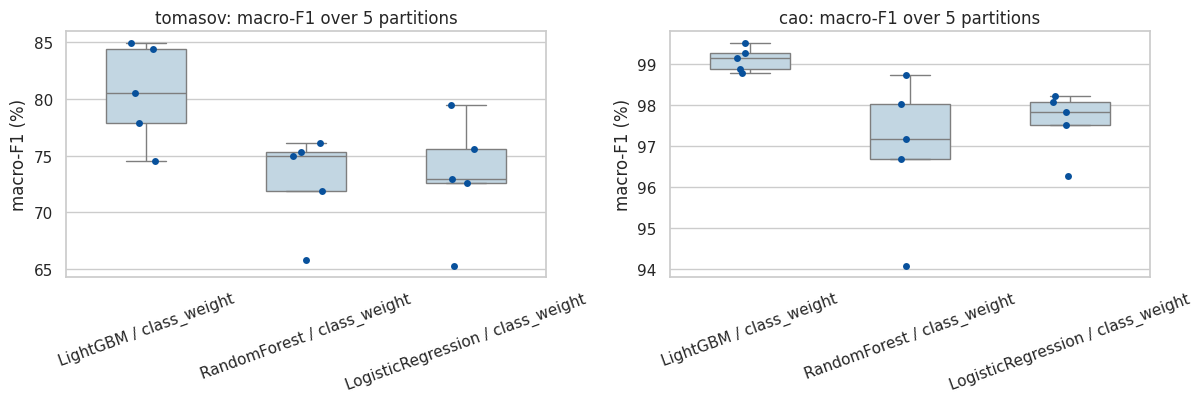

In [4]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.2 * len(DATASETS), 4.2),
                         squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    sub = rep_all[rep_all.dataset == ds]
    sns.boxplot(data=sub, x="condition", y="f1_macro", ax=ax, width=0.5,
                showfliers=False, color="#bdd7e7")
    sns.stripplot(data=sub, x="condition", y="f1_macro", ax=ax,
                  color="#08519c", size=5, jitter=0.12)
    ax.set_title(f"{ds}: macro-F1 over {N_REPEATS} partitions")
    ax.set_xlabel("")
    ax.set_ylabel("macro-F1 (%)")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(out_dir / "repeated_splits.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Group-level bootstrap on the reported test set

The headline configuration is refitted on the stored partition and its test predictions
are resampled at three levels. The window level is the naive interval the original
submission implied; the coarser levels are the honest ones. The width should grow
substantially as the resampling unit becomes a real acquisition unit.

**Which classes enter the macro average.** A replicate that misses a recording also misses
every class unique to it. Scoring those classes as zero would not measure performance, it
would measure the resampling scheme: on Tomasov five of nine classes come from a single
recording each, and with thirteen test recordings a given one is missed about 35% of the
time, which is enough to push the point estimate outside its own interval. Macro-F1 is
therefore averaged over the classes each replicate contains, and
`frac_replicates_all_classes` records how often that is the full set.

**When the interval is not usable.** The `estimable` column is False when the point
estimate falls outside the interval or when fewer than 90% of replicates contain every
class. On this data that is expected for Tomasov macro-F1 at recording level: thirteen
acquisitions cannot support a macro average over nine classes. Report accuracy at
recording level and macro-F1 at zone level, and say why - the same sparsity of independent
acquisitions is what the confound analysis is about.

In [5]:
boot_rows, preds = [], {}
for ds in DATASETS:
    d = DATA[ds]
    model, strategy = HEADLINE[ds]
    sp = d["split"]
    tr, te = sp == "train", sp == "test"
    print(f"=== {ds}: {model} / {strategy}  ({tr.sum():,} train, {te.sum():,} test) ===")
    pred_path = out_dir / f"headline_predictions_{ds}.csv"
    if REUSE_CACHED and pred_path.exists():
        cached = pd.read_csv(pred_path)
        y_true, y_pred = cached["y_true"].to_numpy(), cached["y_pred"].to_numpy()
        print(f"  reusing {pred_path.name}")
    else:
        r = EV.fit_predict(model, strategy, d["X"][tr], d["y"][tr],
                           d["X"][te], d["y"][te], C.SEED)
        y_true, y_pred = d["y"][te], r["y_pred"]
        pd.DataFrame({"y_true": y_true, "y_pred": y_pred}).to_csv(pred_path, index=False)
        print(f"  accuracy {100*r['metrics']['accuracy']:.2f}%  "
              f"macro-F1 {100*r['metrics']['f1_macro']:.2f}%")
    preds[ds] = (y_true, y_pred, d["manifest"][te])

    mte = d["manifest"][te]
    levels = {"window (naive)": np.arange(int(te.sum()))}
    for col in GROUP_COLS[ds]["ladder"]:
        levels[f"{col}"] = mte[col].to_numpy()
    for metric in ("f1_macro", "accuracy"):
        t = R.bootstrap_by_level(y_true, y_pred, levels,
                                 n_boot=N_BOOT, seed=C.SEED, metric=metric)
        t.insert(0, "metric", metric)
        t.insert(0, "dataset", ds)
        boot_rows.append(t)

boot = pd.concat(boot_rows, ignore_index=True)
display(boot)
boot.to_csv(out_dir / "group_bootstrap_ci.csv", index=False)

bad = boot[~boot["estimable"].astype(bool)]
if len(bad):
    print()
    print("NOT ESTIMABLE at this resampling level - do not quote these intervals:")
    for _, r_ in bad.iterrows():
        print(f"  {r_['dataset']:8s} {r_['metric']:9s} {r_['level']:14s} "
              f"n_groups={r_['n_groups']:>5}  "
              f"all classes in {100*r_['frac_replicates_all_classes']:.0f}% of replicates")
else:
    print()
    print("every interval is estimable at its resampling level")

=== tomasov: LightGBM / borderline_smote  (148,229 train, 11,334 test) ===
  reusing headline_predictions_tomasov.csv
=== cao: LightGBM / undersample  (12,155 train, 1,803 test) ===
  reusing headline_predictions_cao.csv


,dataset,metric,level,n_groups,point,ci_low,ci_high,half_width,mean_classes_present,n_classes_total,frac_replicates_all_classes,estimable,n_boot
0,tomasov,f1_macro,window (naive),11334,81.978,81.379,82.619,0.620,9.00,9,1.000,True,2000
1,tomasov,f1_macro,zone_id,35,81.978,70.281,94.032,11.876,7.98,9,0.287,False,2000
2,tomasov,f1_macro,recording_id,13,81.978,63.360,95.178,15.909,6.60,9,0.024,False,2000
3,tomasov,accuracy,window (naive),11334,90.709,90.171,91.221,0.525,9.00,9,1.000,True,2000
4,tomasov,accuracy,zone_id,35,90.709,83.589,95.372,5.891,9.00,9,1.000,True,2000
5,tomasov,accuracy,recording_id,13,90.709,80.816,95.973,7.578,9.00,9,1.000,True,2000
6,cao,f1_macro,window (naive),1803,98.897,98.336,99.397,0.530,6.00,6,1.000,True,2000
7,cao,f1_macro,session_id,44,98.897,97.688,99.372,0.842,5.93,6,0.933,True,2000
8,cao,f1_macro,date_id,18,98.897,97.808,99.464,0.828,5.74,6,0.755,False,2000
9,cao,accuracy,window (naive),1803,99.057,98.613,99.445,0.416,6.00,6,1.000,True,2000



NOT ESTIMABLE at this resampling level - do not quote these intervals:
  tomasov  f1_macro  zone_id        n_groups=   35  all classes in 29% of replicates
  tomasov  f1_macro  recording_id   n_groups=   13  all classes in 2% of replicates
  cao      f1_macro  date_id        n_groups=   18  all classes in 76% of replicates


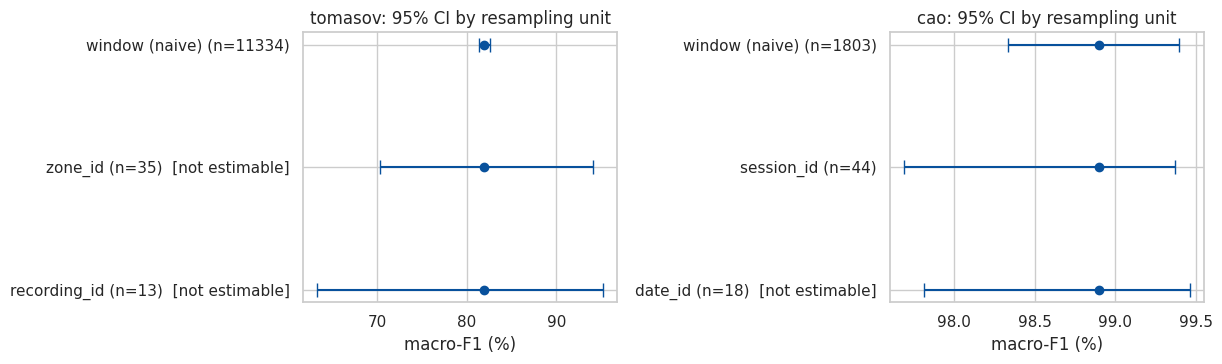

In [6]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.2 * len(DATASETS), 3.8),
                         squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    sub = boot[(boot.dataset == ds) & (boot.metric == "f1_macro")]
    ypos = np.arange(len(sub))
    # Clip the error bars at zero.  A negative arm is a real diagnostic - the
    # point estimate lies outside its interval - but matplotlib raises on it,
    # and the first run of this notebook died here before the paired tests ran.
    lo = np.clip(sub["point"] - sub["ci_low"], 0, None)
    hi = np.clip(sub["ci_high"] - sub["point"], 0, None)
    ax.errorbar(sub["point"], ypos, xerr=[lo, hi], fmt="o", capsize=5,
                color="#08519c")
    ticks = []
    for lvl, n, est in zip(sub["level"], sub["n_groups"], sub["estimable"]):
        ticks.append(f"{lvl} (n={n})" + ("" if est else "  [not estimable]"))
    ax.set_yticks(ypos)
    ax.set_yticklabels(ticks)
    ax.invert_yaxis()
    ax.set_xlabel("macro-F1 (%)")
    ax.set_title(f"{ds}: 95% CI by resampling unit")
plt.tight_layout()
fig.savefig(out_dir / "group_bootstrap_ci.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Paired comparison over independent acquisitions

The direct replacement for the Friedman test. The same six balancing strategies are
compared, but each block is now a **held-out acquisition** - a whole Tomasov recording or
a whole Cao acquisition date - trained on all the others. Those blocks share no samples,
no sensor deployment and no acquisition session, so a paired Wilcoxon over them is a test
of the thing we actually care about.

This is also a much harder evaluation than the within-acquisition split, so the absolute
numbers will be lower. That is the point: the ranking is what is being tested, not the
level.

**Two rules make the metric mean something.** Classes confined to a single acquisition are
dropped, because holding that acquisition out removes the class from training altogether -
five of the nine Tomasov classes are in exactly that position, which is why notebook 08
restricted its leave-one-recording-out study to the four classes with two or more
recordings. And macro-F1 is averaged over the classes the held-out unit actually contains,
because `score_all` averages over the union of true and predicted labels, so a class the
model predicts but which is absent from that acquisition contributes a zero.

**Accuracy is the primary paired metric here**, since it is unaffected by class absence.
Macro-F1 over present classes is reported alongside it, and the uncorrected
`f1_macro_union` is kept so the correction is auditable.

**On Tomasov the paired test can only use accuracy.** All sixteen recordings contain
exactly one event class, so a held-out recording never yields a multi-class test set and
macro-F1 is left as NaN there. For a one-class fold, accuracy is recall on the held-out
class, which is exactly what notebook 08 reports for its leave-one-recording-out study.
Cao dates do hold several classes, so both metrics are available there.

In [7]:
loo_path = out_dir / "leave_one_acquisition_out_scores.csv"
loo_cached = pd.read_csv(loo_path) if (REUSE_CACHED and loo_path.exists()) else None
if loo_cached is not None:
    print(f"reusing {loo_path.name} ({len(loo_cached)} rows). "
          f"Set REUSE_CACHED = False to recompute.")

loo_all, pair_all = [], []
for ds in DATASETS:
    d = DATA[ds]
    col = GROUP_COLS[ds]["loo"]
    idx = R.subsample_index(d["y"], LOO_PER_CLASS, C.SEED)
    X, y = d["X"][idx], d["y"][idx]
    groups = d["manifest"].iloc[idx][col].to_numpy()
    print(f"=== {ds}: leave-one-{col}-out over {len(np.unique(groups))} units ===")
    if loo_cached is not None and (loo_cached["dataset"] == ds).any():
        sc = loo_cached[loo_cached["dataset"] == ds].reset_index(drop=True)
        print(f"  reused {len(sc)} cached rows")
    else:
        t0 = time.perf_counter()
        sc = R.leave_one_group_out_scores(X, y, groups, PAIRED_CONFIGS, seed=C.SEED)
        sc["dataset"] = ds
        sc["unit"] = col
        print(f"  {time.perf_counter()-t0:.0f}s")
    loo_all.append(sc)

    if not len(sc):
        print(f"  {ds}: no acquisition unit was scorable - no paired test possible. "
              f"Check LOO_PER_CLASS and the per-unit class counts above.")
    for metric in ("accuracy", "f1_macro"):
        pc = R.paired_group_comparison(sc, metric=metric)
        if not len(pc):
            print(f"  {ds}/{metric}: nothing to compare "
                  f"(fewer than 3 units or fewer than 2 conditions with a value)")
            continue
        pc.insert(0, "metric", metric)
        pc.insert(0, "dataset", ds)
        pair_all.append(pc)

loo_all = pd.concat(loo_all, ignore_index=True) if loo_all else pd.DataFrame()
pair_all = (pd.concat(pair_all, ignore_index=True) if pair_all
            else pd.DataFrame(columns=["dataset", "metric", "condition_a",
                                       "condition_b", "p_holm",
                                       "significant_005"]))
loo_all.to_csv(out_dir / "leave_one_acquisition_out_scores.csv", index=False)
pair_all.to_csv(out_dir / "paired_wilcoxon_holm.csv", index=False)

if len(loo_all):
    print("held-out units actually scored:")
    display(loo_all.groupby(["dataset", "unit"])["held_out"].nunique()
            .rename("n_units").to_frame())
else:
    print("no leave-one-acquisition-out results at all - test 3 did not run")
print("mean accuracy per condition, averaged over held-out acquisitions:")
display(loo_all.groupby(["dataset", "condition"])["accuracy"]
        .agg(["count", "mean", "std"]).round(2))
print("mean macro-F1 (over classes present in each held-out unit):")
display(loo_all.groupby(["dataset", "condition"])["f1_macro"]
        .agg(["count", "mean", "std"]).round(2))
print("pairwise tests (Holm-corrected):")
display(pair_all.round(4))

=== tomasov: leave-one-recording_id-out over 16 units ===
  dropping 5 single-unit class(es): ['construction', 'manipulation', 'openclose', 'regular', 'running']


/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py

  auto2_2023-04-17T124510+01   n=    98 k=1  acc none= 73.5  class_weight= 73.5  undersample= 74.5  smote= 73.5  borderline_smote= 75.5  smote_tomek= 70.4


/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py

  auto4_2023-06-06T144655+01   n=   318 k=1  acc none= 99.1  class_weight= 99.4  undersample= 98.7  smote= 99.1  borderline_smote= 99.4  smote_tomek= 99.1


/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/home/agx_orin/anaconda3/envs/jetson_torch/lib/python3.10/site-packages/sklearn/metrics/_classification.py

... (66 outputs left out)

mean macro-F1 (over classes present in each held-out unit):


count   mean    std
dataset condition                                       
cao     LightGBM / borderline_smote     10  88.09  16.68
        LightGBM / class_weight         10  88.19  16.74
        LightGBM / none                 10  88.05  16.69
        LightGBM / smote                10  88.09  16.83
        LightGBM / smote_tomek          10  87.46  17.50
        LightGBM / undersample          10  88.61  16.43
tomasov LightGBM / borderline_smote      0    NaN    NaN
        LightGBM / class_weight          0    NaN    NaN
        LightGBM / none                  0    NaN    NaN
        LightGBM / smote                 0    NaN    NaN
        LightGBM / smote_tomek           0    NaN    NaN
        LightGBM / undersample           0    NaN    NaN

pairwise tests (Holm-corrected):


,dataset,metric,condition_a,condition_b,n_units,mean_diff,median_diff,wins_a,wins_b,wilcoxon_stat,p_value,p_holm,significant_005
0,tomasov,accuracy,LightGBM / borderline_smote,LightGBM / class_weight,11,1.436,1.483,10,0,0.0,0.0020,0.0293,True
1,tomasov,accuracy,LightGBM / class_weight,LightGBM / undersample,11,-5.127,-2.878,1,10,2.0,0.0029,0.0410,True
2,tomasov,accuracy,LightGBM / none,LightGBM / undersample,11,-5.827,-2.590,1,9,1.0,0.0039,0.0508,False
3,tomasov,accuracy,LightGBM / smote,LightGBM / undersample,11,-4.571,-2.224,2,9,3.0,0.0049,0.0586,False
4,tomasov,accuracy,LightGBM / borderline_smote,LightGBM / none,11,2.137,2.041,10,1,4.0,0.0068,0.0752,False
5,tomasov,accuracy,LightGBM / borderline_smote,LightGBM / undersample,11,-3.690,-1.250,3,8,7.0,0.0186,0.1855,False
6,tomasov,accuracy,LightGBM / smote_tomek,LightGBM / undersample,11,-3.349,-3.310,3,8,7.0,0.0186,0.1670,False
7,tomasov,accuracy,LightGBM / borderline_smote,LightGBM / smote,11,0.881,0.593,8,3,13.0,0.0830,0.6641,False
8,tomasov,accuracy,LightGBM / none,LightGBM / smote_tomek,11,-2.478,-1.786,3,7,10.0,0.0840,0.5879,False
9,tomasov,accuracy,LightGBM / class_weight,LightGBM / smote_tomek,11,-1.778,-1.927,4,7,15.0,0.1230,0.7383,False


In [8]:
flag = (pair_all["significant_005"].fillna(False)
        if "significant_005" in pair_all.columns
        else pd.Series(False, index=pair_all.index))
sig = pair_all[flag.astype(bool)]
print(f"{len(sig)} of {len(pair_all)} pairwise comparisons survive Holm correction")
if len(sig):
    display(sig[["dataset", "condition_a", "condition_b", "n_units",
                 "mean_diff", "p_value", "p_holm"]].round(4))
else:
    print("No pair separates once the blocks are independent acquisitions.")
    print("That is a defensible result and the paper should state it plainly:")
    print("the choice of balancing strategy does not survive a test whose units")
    print("are separate acquisitions, and the original Friedman significance was")
    print("an artefact of blocking on configurations of a single partition.")

verdict = {
    "n_pairs": int(len(pair_all)),
    "n_significant_holm": int(len(sig)),
    "repeat_sd_f1_macro": {
        ds: float(np.nan_to_num(
            R.repeat_summary(rep_all[rep_all.dataset == ds])["sd"].max()))
        for ds in DATASETS},
    "bootstrap_widening": {
        ds: {row["level"]: float(2 * row["half_width"])
             for _, row in boot[(boot.dataset == ds) &
                                (boot.metric == "f1_macro")].iterrows()}
        for ds in DATASETS},
    "bootstrap_not_estimable": [
        f"{r_['dataset']}/{r_['metric']}/{r_['level']}"
        for _, r_ in boot[~boot["estimable"].astype(bool)].iterrows()],
    "note": ("Friedman/Nemenyi over balancing strategies is retired; see the "
             "three tests in this notebook."),
}
(out_dir / "statistics_verdict.json").write_text(json.dumps(verdict, indent=2),
                                                 encoding="utf-8")
print(json.dumps(verdict, indent=2))

2 of 45 pairwise comparisons survive Holm correction


,dataset,condition_a,condition_b,n_units,mean_diff,p_value,p_holm
0,tomasov,LightGBM / borderline_smote,LightGBM / class_weight,11,1.436,0.0020,0.0293
1,tomasov,LightGBM / class_weight,LightGBM / undersample,11,-5.127,0.0029,0.0410


{
  "n_pairs": 45,
  "n_significant_holm": 2,
  "repeat_sd_f1_macro": {
    "tomasov": 5.221,
    "cao": 1.792
  },
  "bootstrap_widening": {
    "tomasov": {
      "window (naive)": 1.24,
      "zone_id": 23.752,
      "recording_id": 31.818
    },
    "cao": {
      "window (naive)": 1.06,
      "session_id": 1.684,
      "date_id": 1.656
    }
  },
  "bootstrap_not_estimable": [
    "tomasov/f1_macro/zone_id",
    "tomasov/f1_macro/recording_id",
    "cao/f1_macro/date_id"
  ],
  "note": "Friedman/Nemenyi over balancing strategies is retired; see the three tests in this notebook."
}


## 3b. Reconciling the 98.90 to 57.82 drop that R2C5 cites

R2C5 quotes the Cao leave-one-date-out macro-F1 falling from 98.90 to 57.82 as evidence of
extreme acquisition-to-acquisition variation. That number comes from notebook 08, and it
needs a correction before it can carry an argument.

Seven of the ten held-out dates contain only two to four of the six classes. Because
macro-F1 was averaged over the union of true and predicted labels, every class the model
predicted on a date where that class does not occur scored zero. Date 220113 is the clearest
case: 98.56% accuracy, 49.62 macro-F1.

The variation is real, but it is smaller than 57.82 suggests, and it is concentrated in two
dates rather than spread across all ten. The cell below recomputes both conventions from the
stored notebook 08 output so the manuscript can quote the corrected figure and say what
changed.

In [9]:
lodo_path = C.RESULTS_DIR / "shared" / "08_crossdataset" / "cao_leave_one_date_out.csv"
if lodo_path.exists():
    lodo = pd.read_csv(lodo_path)
    display(lodo.round(2))
    print(f"dates evaluated                       : {len(lodo)}")
    print(f"dates holding fewer than 6 classes    : "
          f"{int((lodo['n_classes_in_test'] < 6).sum())}")
    print(f"mean macro-F1 as published (union)    : {lodo['f1_macro'].mean():.2f}")
    print(f"mean accuracy                         : {lodo['accuracy'].mean():.2f}")
    print(f"worst two dates by accuracy           : "
          f"{', '.join(lodo.nsmallest(2, 'accuracy')['held_out_date'].astype(str))}")
    card = json.loads((C.results_dir("cao", "07_final", FEATURE_SET) / "model_card.json")
                      .read_text(encoding="utf-8"))
    within = round(float(card["test"]["accuracy"]), 2)     # notebook 07's headline
    print()
    print(f"within-dataset accuracy               : {within:.2f}")
    print(f"drop in accuracy across dates          : "
          f"{within - lodo['accuracy'].mean():.2f} pp")
    lodo_fix = {
        "n_dates": int(len(lodo)),
        "n_dates_missing_classes": int((lodo["n_classes_in_test"] < 6).sum()),
        "published_macro_f1_union": round(float(lodo["f1_macro"].mean()), 2),
        "mean_accuracy": round(float(lodo["accuracy"].mean()), 2),
        "within_dataset_accuracy": within,
        "accuracy_drop_pp": round(within - float(lodo["accuracy"].mean()), 2),
        "note": ("macro-F1 was averaged over union(y_true, y_pred); on dates holding "
                 "a subset of the classes this scores absent classes as zero. "
                 "Accuracy is unaffected and is the figure the manuscript should lead "
                 "with, with the two genuinely failing dates named."),
    }
    (out_dir / "cao_lodo_reconciliation.json").write_text(
        json.dumps(lodo_fix, indent=2), encoding="utf-8")
    print()
    print("wrote", out_dir / "cao_lodo_reconciliation.json")
else:
    print("notebook 08 output not found at", lodo_path)
    print("Run notebook 08 first, or copy cao_leave_one_date_out.csv into place.")

,held_out_date,n_test,n_classes_in_test,accuracy,f1_macro
0,220112,831,2,100.00,100.00
1,220113,626,2,98.56,49.62
2,220116,2130,3,84.51,57.31
3,220117,1690,5,98.93,88.31
4,220121,912,2,99.45,49.85
5,220122,2298,4,91.30,61.77
6,220418,43,2,97.67,66.04
7,220509,359,2,97.21,45.40
8,220517,1853,4,48.84,33.20
9,220518,825,2,51.64,26.74


dates evaluated                       : 10
dates holding fewer than 6 classes    : 10
mean macro-F1 as published (union)    : 57.82
mean accuracy                         : 86.81
worst two dates by accuracy           : 220517, 220518

within-dataset accuracy               : 99.06
drop in accuracy across dates          : 12.25 pp

wrote /mnt/b6bdcd1c-136a-435b-aeed-0e1b31c32749/Paper_Reeyan/Results/shared/14_statistics/cao_lodo_reconciliation.json


## 4. What the paper now says

Replace Table 14 and its critical-difference diagram with three items:

0. **Correct the acquisition-variation figure.** The 98.90 to 57.82 drop quoted in the
   manuscript, and repeated by the reviewer, is partly an artefact of averaging macro-F1
   over classes absent from the held-out date. Quote accuracy instead, name the two dates
   that genuinely fail, and say what was corrected - from `cao_lodo_reconciliation.json`.
1. **Partition variance.** Report mean and standard deviation of macro-F1 across the five
   repeated partitions for the headline configuration, from
   `repeated_splits_summary.csv`. Every headline number in the paper should carry that
   standard deviation.
2. **Honest intervals.** Report the recording-level (Tomasov) and date-level (Cao) 95%
   bootstrap intervals from `group_bootstrap_ci.csv`, and state in one sentence how much
   narrower the naive window-level interval was. That single comparison makes the
   dependence argument concretely rather than rhetorically.
3. **Paired tests where they are valid.** Report the Holm-corrected Wilcoxon results from
   `paired_wilcoxon_holm.csv`, blocked on held-out acquisitions.

State explicitly that the Friedman/Nemenyi analysis has been withdrawn, and why. A
withdrawn test that is explained is a strength; a defended one that the reviewer has
already seen through is not.

If test 3 finds no significant pair, say so. The claim of the paper is about the leakage
protocol and the multi-domain feature set, not about which resampler wins - and a null
result on the resampler comparison costs the paper nothing.